In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

print("P05 environment ready!")

P05 environment ready!


In [5]:
# Dataset location
DATA_PATH = Path(r"..\data\raw\IMDB Dataset.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check sentiment distribution
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

# Check sentiment percentages
print("\nSentiment percentages:")
print((df["sentiment"].value_counts(normalize=True) * 100).round(2))

# Check duplicate reviews
print("\nExact duplicate reviews:", df.duplicated(subset=["review"]).sum())

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64

Exact duplicate reviews: 418


In [7]:
# Calculate review length in words
df["review_length"] = df["review"].str.split().str.len()

# Summary statistics by sentiment
print(df.groupby("sentiment")["review_length"].describe().round(2))

             count    mean     std   min    25%    50%    75%     max
sentiment                                                            
negative   25000.0  229.46  164.95   4.0  128.0  174.0  278.0  1522.0
positive   25000.0  232.85  177.50  10.0  125.0  172.0  284.0  2470.0


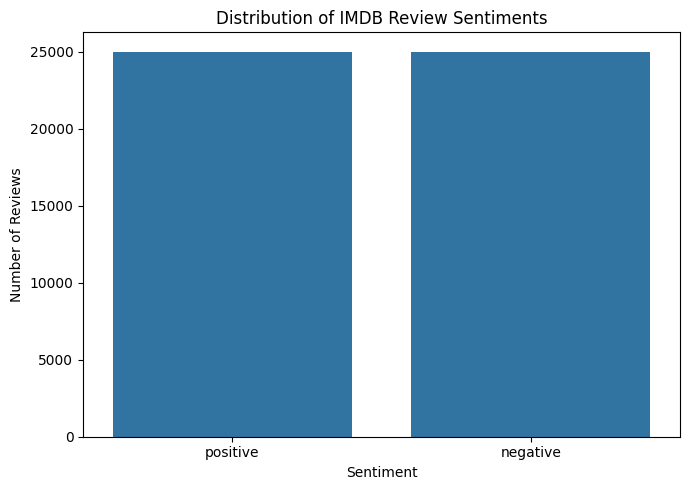

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sentiment")

plt.title("Distribution of IMDB Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

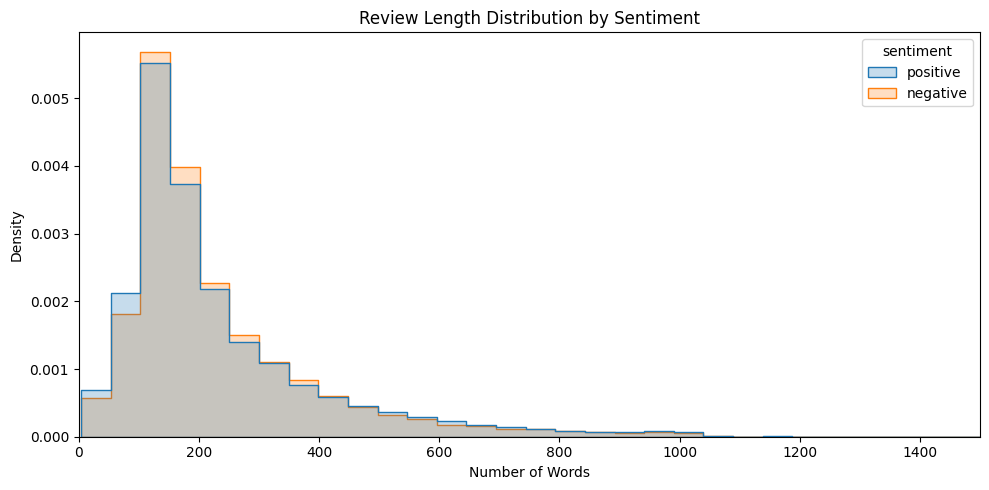

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, 1500)
plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [10]:
# EDA: inspect representative review examples
for i, row in df.head(5).iterrows():
    print(f"\nReview {i + 1}")
    print("Sentiment:", row["sentiment"])
    print("Text:", row["review"][:1000])
    print("-" * 80)


Review 1
Sentiment: positive
Text: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main 

In [11]:
# Data quality: quantify exact duplicates and conflicting labels
duplicate_count = df.duplicated(subset=["review"]).sum()

# Count unique reviews
unique_count = df["review"].nunique()

# Check reviews that have conflicting sentiment labels
label_counts = df.groupby("review")["sentiment"].nunique()
conflicting_count = (label_counts > 1).sum()

print("Total reviews:", len(df))
print("Exact duplicate rows:", duplicate_count)
print("Unique review texts:", unique_count)
print("Unique reviews with conflicting labels:", conflicting_count)

Total reviews: 50000
Exact duplicate rows: 418
Unique review texts: 49582
Unique reviews with conflicting labels: 0


In [12]:
# Data quality: inspect duplicate-label conflicts before handling duplicates
label_counts = df.groupby("review")["sentiment"].nunique()
conflicting_reviews = label_counts[label_counts > 1].index

print("Rows before duplicate handling:", len(df))
print("Rows with conflicting review labels:",
      df["review"].isin(conflicting_reviews).sum())

print("Rows after removing exact duplicate texts:",
      len(df.drop_duplicates(subset=["review"])))

Rows before duplicate handling: 50000
Rows with conflicting review labels: 0
Rows after removing exact duplicate texts: 49582


In [13]:
# Prepare unique-review view and compare sentiment counts
df_unique = df.drop_duplicates(subset=["review"]).copy()

print("Unique dataset shape:", df_unique.shape)
print("\nSentiment distribution after deduplication:")
print(df_unique["sentiment"].value_counts())

Unique dataset shape: (49582, 3)

Sentiment distribution after deduplication:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [14]:
# Reproducible, group-aware train/test split (duplicate text cannot cross splits)
X = df["review"].fillna("").astype(str)
y = df["sentiment"].astype(str)

# Keep identical review texts in the same group to prevent leakage
groups = pd.factorize(X)[0]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)
y_train = y.iloc[train_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)

print("Training reviews:", len(X_train))
print("Test reviews:", len(X_test))
print("\nTraining sentiment distribution:")
print(y_train.value_counts())
print("\nTest sentiment distribution:")
print(y_test.value_counts())
print("\nOverlapping review texts:", len(set(X_train) & set(X_test)))

Training reviews: 40006
Test reviews: 9994

Training sentiment distribution:
sentiment
positive    20004
negative    20002
Name: count, dtype: int64

Test sentiment distribution:
sentiment
negative    4998
positive    4996
Name: count, dtype: int64

Overlapping review texts: 0


In [15]:
# Validate the held-out split and check for text leakage
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

overlap = set(X_train) & set(X_test)
print("Overlapping review texts:", len(overlap))

print("\nTraining distribution:")
print(y_train.value_counts())
print("\nTest distribution:")
print(y_test.value_counts())

print("\nSplit checks")
print("No duplicate text leakage:", len(overlap) == 0)
print("Test size is approximately 20%:", abs(len(X_test) / len(df) - 0.20) < 0.02)

Training samples: 40006
Test samples: 9994
Overlapping review texts: 0

Training distribution:
sentiment
positive    20004
negative    20002
Name: count, dtype: int64

Test distribution:
sentiment
negative    4998
positive    4996
Name: count, dtype: int64

Split checks
No duplicate text leakage: True
Test size is approximately 20%: True


In [16]:
# Cross-validation folds on training data only; preserve the held-out test set
# The held-out test set is not used in cross-validation.
cv_groups = pd.factorize(X_train)[0]
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold cross-validation on training data")
for fold, (fold_train_idx, fold_valid_idx) in enumerate(
    cv.split(X_train, y_train, groups=cv_groups), start=1
):
    fold_train_reviews = X_train.iloc[fold_train_idx]
    fold_valid_reviews = X_train.iloc[fold_valid_idx]
    overlap = set(fold_train_reviews) & set(fold_valid_reviews)

    print(
        f"Fold {fold}: "
        f"train={len(fold_train_idx)}, "
        f"validation={len(fold_valid_idx)}, "
        f"overlap={len(overlap)}"
    )

5-fold cross-validation on training data
Fold 1: train=32005, validation=8001, overlap=0
Fold 2: train=32005, validation=8001, overlap=0
Fold 3: train=32005, validation=8001, overlap=0
Fold 4: train=32004, validation=8002, overlap=0
Fold 5: train=32005, validation=8001, overlap=0


In [17]:
# Save the shared split for downstream modeling notebooks
if Path("data").is_dir():
    REPO_ROOT = Path(".")
else:
    REPO_ROOT = Path("..")

processed_dir = REPO_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.DataFrame({"review": X_train, "sentiment": y_train})
test_df = pd.DataFrame({"review": X_test, "sentiment": y_test})

train_df.to_csv(processed_dir / "train.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)

print("Saved train.csv:", train_df.shape)
print("Saved test.csv:", test_df.shape)

Saved train.csv: (40006, 2)
Saved test.csv: (9994, 2)


In [18]:
# Verify the split files saved in the previous cell
train_path = processed_dir / "train.csv"
test_path = processed_dir / "test.csv"

print("Training file exists:", train_path.exists())
print("Test file exists:", test_path.exists())

if train_path.exists() and test_path.exists():
    print("Saved training rows:", len(pd.read_csv(train_path)))
    print("Saved test rows:", len(pd.read_csv(test_path)))

Training file exists: True
Test file exists: True
Saved training rows: 40006
Saved test rows: 9994


In [21]:
# Reload saved split, verify integrity, and report Checkpoint 1 baseline
train_path = processed_dir / "train.csv"
test_path = processed_dir / "test.csv"

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("TRAIN-TEST SPLIT")
print("-" * 40)
print("Training rows:", len(train))
print("Test rows:", len(test))

print("\nTRAINING SENTIMENT DISTRIBUTION")
print(train["sentiment"].value_counts())
print("\nTraining percentages:")
print((train["sentiment"].value_counts(normalize=True) * 100).round(2))

print("\nTEST SENTIMENT DISTRIBUTION")
print(test["sentiment"].value_counts())
print("\nTest percentages:")
print((test["sentiment"].value_counts(normalize=True) * 100).round(2))

train_reviews = set(train["review"].astype(str))
test_reviews = set(test["review"].astype(str))
overlap = train_reviews.intersection(test_reviews)

print("\nDUPLICATE LEAKAGE CHECK")
print("-" * 40)
print("Overlapping unique review texts:", len(overlap))
print("No overlapping review texts:", len(overlap) == 0)



TRAIN-TEST SPLIT
----------------------------------------
Training rows: 40006
Test rows: 9994

TRAINING SENTIMENT DISTRIBUTION
sentiment
positive    20004
negative    20002
Name: count, dtype: int64

Training percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64

TEST SENTIMENT DISTRIBUTION
sentiment
negative    4998
positive    4996
Name: count, dtype: int64

Test percentages:
sentiment
negative    50.01
positive    49.99
Name: proportion, dtype: float64

DUPLICATE LEAKAGE CHECK
----------------------------------------
Overlapping unique review texts: 0
No overlapping review texts: True


In [20]:
# Simple majority-class baseline required for Checkpoint 1
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(train), 1)), train["sentiment"])
baseline_predictions = baseline.predict(np.zeros((len(test), 1)))

print("\nMAJORITY-CLASS BASELINE")
print("Test accuracy:", round(accuracy_score(test["sentiment"], baseline_predictions), 4))


MAJORITY-CLASS BASELINE
Test accuracy: 0.4999
